<a href="https://colab.research.google.com/github/surajgade17/molecular-similarity-search/blob/main/molecular_similarity_search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Molecular Similarity Search
Finds the most similar molecules to a query using Morgan fingerprints and Tanimoto similarity, then tests how well "similar molecules have similar solubility" holds.
## Step 1: Build the search

In [1]:
!pip -q install rdkit
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

url = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"
df = pd.read_csv(url).rename(columns={"measured log solubility in mols per litre": "logS"})[["smiles", "logS"]]
mols = [Chem.MolFromSmiles(s) for s in df.smiles]
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(m) for m in mols]

def search(smiles, k=5):
    q = Chem.MolFromSmiles(smiles)
    sims = np.array(DataStructs.BulkTanimotoSimilarity(gen.GetFingerprint(q), fps))
    idx = np.argsort(sims)[::-1][:k]
    return pd.DataFrame({"smiles": df.smiles.iloc[idx].values,
                         "tanimoto": sims[idx].round(3),
                         "logS": df.logS.iloc[idx].values})

print("Aspirin:");   display(search("CC(=O)OC1=CC=CC=C1C(=O)O"))
print("Ibuprofen:"); display(search("CC(C)CC1=CC=C(C=C1)C(C)C(=O)O"))

Aspirin:


,smiles,tanimoto,logS
0,COC(=O)c1ccccc1C(=O)OC,0.400,-1.660
1,CC(=O)c1ccccc1,0.379,-1.280
2,CNC(=O)Oc1ccccc1C(C)C,0.368,-2.863
3,CCOC(=O)c1ccccc1C(=O)OCC,0.364,-2.350
4,O=C(c1ccccc1)c2ccccc2,0.357,-3.120


Ibuprofen:


,smiles,tanimoto,logS
0,CC(C)Cc1ccccc1,0.500,-4.120
1,CC(O)c1ccccc1,0.281,-0.920
2,CC(C)c1ccc(NC(=O)N(C)C)cc1,0.275,-3.536
3,CN(C)C(=O)C(c1ccccc1)c2ccccc2,0.270,-2.980
4,CC(C)N(C(=O)CCl)c1ccccc1,0.268,-2.480


## Step 2: Does similarity predict solubility?
For each molecule, find its nearest neighbour (excluding itself) and compare their logS values. If similar molecules have similar solubility, the error should shrink as similarity rises.

Nearest-neighbour error by similarity:


,count,mean
bin,,
<0.3,72,1.44
0.3-0.5,263,1.23
0.5-0.7,506,1.14
>=0.7,287,0.87


Correlation (nearest-neighbour logS vs true logS): r = 0.75


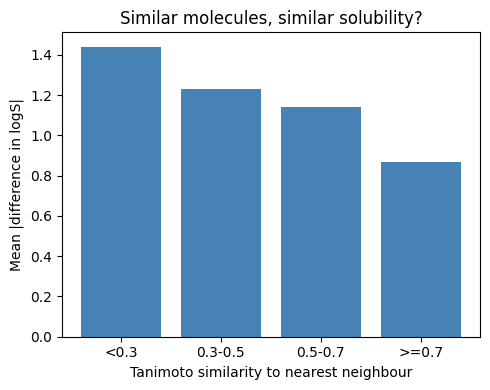

In [2]:
rows = []
for i, fp in enumerate(fps):
    s = np.array(DataStructs.BulkTanimotoSimilarity(fp, fps))
    s[i] = -1                       # exclude the molecule itself
    j = s.argmax()
    rows.append((s[j], abs(df.logS.iloc[i] - df.logS.iloc[j]), df.logS.iloc[j]))
nn = pd.DataFrame(rows, columns=["sim", "abs_err", "nn_logS"])
nn["bin"] = pd.cut(nn.sim, [0, 0.3, 0.5, 0.7, 1.01], right=False,
                   labels=["<0.3", "0.3-0.5", "0.5-0.7", ">=0.7"])
tab = nn.groupby("bin", observed=True).abs_err.agg(["count", "mean"]).round(2)
print("Nearest-neighbour error by similarity:")
display(tab)
print("Correlation (nearest-neighbour logS vs true logS): r =",
      round(np.corrcoef(nn.nn_logS, df.logS)[0, 1], 2))

plt.figure(figsize=(5, 4))
plt.bar(tab.index.astype(str), tab["mean"], color="steelblue")
plt.xlabel("Tanimoto similarity to nearest neighbour")
plt.ylabel("Mean |difference in logS|")
plt.title("Similar molecules, similar solubility?")
plt.tight_layout(); plt.savefig("similarity_vs_error.png", dpi=150); plt.show()
tab.to_csv("similarity_error_by_bin.csv")

In [3]:
from google.colab import files
files.download("similarity_vs_error.png"); files.download("similarity_error_by_bin.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>